# Entrega 4 – Visión Artificial (ITM)
## Clasificación de defectos superficiales en acero laminado en caliente
### Transfer Learning (MobileNetV2) + AutoGluon como cabeza de decisión

**Problema de ingeniería.** En una línea de laminación en caliente la banda de acero sale a alta velocidad y la inspección visual humana es lenta, subjetiva y cansada. Un sistema de visión que clasifique automáticamente el tipo de defecto permite: separar material no conforme, ajustar el proceso (rodillos, descascarillado, temperatura) y llevar estadística de calidad.

**Dataset.** *NEU Surface Defect Database* (Northeastern University, Song & Yan). 1.800 imágenes en escala de grises de 200×200 px, **6 clases balanceadas (300 c/u)**:

| Clase | Descripción | Causa típica |
|---|---|---|
| `crazing` | Red de fisuras finas | Tensiones térmicas |
| `inclusion` | Partículas no metálicas incrustadas | Escoria / impurezas |
| `patches` | Manchas o parches | Óxido, contaminación |
| `pitted_surface` | Picaduras | Corrosión, cascarilla |
| `rolled-in_scale` | Cascarilla laminada | Descascarillado deficiente |
| `scratches` | Rayones | Contacto con rodillos/guías |

**Flujo del sistema**

`Imagen → tf.data (redimensionar, normalizar, lotes) → MobileNetV2 congelada (embeddings 1280-D) → DataFrame f_0…f_1279 + etiqueta → AutoGluon TabularPredictor → clase`

> Estructura de carpetas esperada: `dataset_NEU/<nombre_clase>/*.png` en la misma carpeta de este notebook.

In [1]:
# ==== 1. Librerías y configuración ====
import os, time, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             f1_score, roc_curve, auc, roc_auc_score)
from sklearn.preprocessing import label_binarize

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR   = "dataset_NEU"      # carpeta con una subcarpeta por clase
IMG_SIZE   = (224, 224)         # tamaño de entrada de MobileNetV2
BATCH_SIZE = 32
SALIDAS    = "salidas_E4"       # aquí se guardan tablas, figuras y modelos
os.makedirs(SALIDAS, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: []


## 2. Carga del dataset y exploración

In [2]:
CLASES = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
rutas, etiquetas = [], []
for idx, clase in enumerate(CLASES):
    archivos = sorted(glob.glob(os.path.join(DATA_DIR, clase, "*")))
    archivos = [a for a in archivos if a.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))]
    rutas += archivos
    etiquetas += [idx] * len(archivos)

rutas = np.array(rutas); etiquetas = np.array(etiquetas, dtype=np.int32)
print("Clases:", CLASES)
print("Total de imágenes:", len(rutas))
print(pd.Series(etiquetas).map(dict(enumerate(CLASES))).value_counts())

Clases: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Total de imágenes: 1800
crazing            300
inclusion          300
patches            300
pitted_surface     300
rolled-in_scale    300
scratches          300
Name: count, dtype: int64


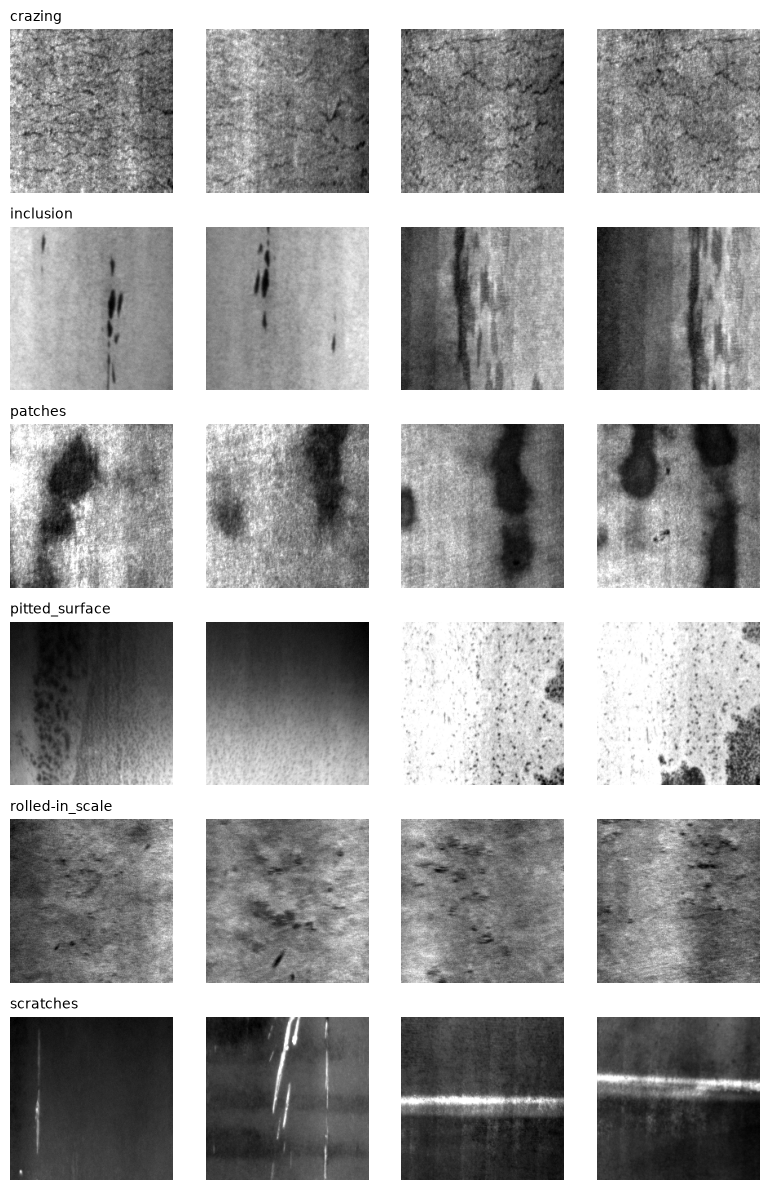

In [3]:
# Muestra visual: 4 ejemplos por clase
fig, axes = plt.subplots(len(CLASES), 4, figsize=(8, 12))
for i, clase in enumerate(CLASES):
    ejemplos = rutas[etiquetas == i][:4]
    for j, ruta in enumerate(ejemplos):
        axes[i, j].imshow(plt.imread(ruta), cmap="gray")
        axes[i, j].axis("off")
    axes[i, 0].set_title(clase, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(f"{SALIDAS}/muestras.png", dpi=120); plt.show()

### División estratificada 70 / 15 / 15
Se fija la semilla y se guarda la partición en `splits.csv` para que la **Entrega 5 (destilación)** use exactamente las mismas imágenes de prueba y la comparación sea justa.

In [4]:
r_train, r_tmp, y_train, y_tmp = train_test_split(rutas, etiquetas, test_size=0.30,
                                                  stratify=etiquetas, random_state=SEED)
r_val, r_test, y_val, y_test = train_test_split(r_tmp, y_tmp, test_size=0.50,
                                                stratify=y_tmp, random_state=SEED)

splits = pd.concat([
    pd.DataFrame({"ruta": r_train, "label": y_train, "split": "train"}),
    pd.DataFrame({"ruta": r_val,   "label": y_val,   "split": "val"}),
    pd.DataFrame({"ruta": r_test,  "label": y_test,  "split": "test"}),
])
splits.to_csv("splits.csv", index=False)
with open("clases.json", "w") as f:
    json.dump(CLASES, f)
print(splits.groupby("split").size())

split
test      270
train    1260
val       270
dtype: int64


## 3. Selección y justificación de la arquitectura base

Se compararon las redes sugeridas en la rúbrica (valores de Keras Applications, sin la capa superior):

| Red | Parámetros (sin top) | Embedding | Comentario |
|---|---|---|---|
| ResNet50 | ~23,6 M | 2048 | Muy precisa pero pesada para CPU / edge |
| DenseNet121 | ~7,0 M | 1024 | Buenas texturas, inferencia lenta por concatenaciones |
| EfficientNetB0 | ~4,0 M | 1280 | Excelente precisión/parámetro |
| **MobileNetV2** | **~2,3 M** | **1280** | **Diseñada para móviles/edge; convoluciones separables en profundidad** |

**¿Por qué MobileNetV2 para este problema?**
1. **Características visuales del problema:** los defectos son *texturas* (fisuras, picaduras, rayas) más que objetos. Los filtros de las primeras capas preentrenadas en ImageNet (bordes, orientaciones, patrones repetitivos) describen muy bien estas texturas; no se necesita una red profunda y pesada.
2. **Recursos de cómputo:** el equipo trabaja en portátiles sin GPU (Anaconda). MobileNetV2 extrae los embeddings de las 1.800 imágenes en pocos segundos en CPU.
3. **Despliegue:** el objetivo final (Entrega 5) es una cámara en línea con un equipo embebido; MobileNetV2 nació justamente para ese escenario.
4. **Las imágenes son en gris:** se replica el canal gris en 3 canales (R=G=B) para reutilizar los pesos de ImageNet sin modificar la red.

## 4. Pipeline con `tf.data.Dataset`
`process_path` hace: **leer archivo → decodificar → 3 canales → redimensionar a 224×224 → normalizar** con `preprocess_input` de MobileNetV2 (rango [-1, 1]). Luego `batch(32)` y `prefetch` para que la CPU prepare el siguiente lote mientras la red procesa el actual.

In [5]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def process_path(ruta, label):
    img = tf.io.read_file(ruta)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)  # gris -> 3 canales
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(tf.cast(img, tf.float32))                    # [0,255] -> [-1,1]
    return img, label

def crear_dataset(rutas, labels):
    ds = tf.data.Dataset.from_tensor_slices((rutas, labels))
    ds = ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)   # SIN shuffle: conserva el orden

ds_train = crear_dataset(r_train, y_train)
ds_val   = crear_dataset(r_val,   y_val)
ds_test  = crear_dataset(r_test,  y_test)

x_b, y_b = next(iter(ds_train))
print("Lote:", x_b.shape, "| rango:", float(tf.reduce_min(x_b)), "a", float(tf.reduce_max(x_b)))

Lote: (32, 224, 224, 3) | rango: -1.0 a 1.0


## 5. Extractor de características (pesos congelados)
`include_top=False` elimina el clasificador de ImageNet; `pooling='avg'` aplica *Global Average Pooling* y entrega un vector de **1280 características** por imagen; `trainable=False` congela todos los pesos.

In [6]:
def crear_extractor_caracteristicas(input_shape=(224, 224, 3)):
    base_model = keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape,
        pooling="avg",
    )
    base_model.trainable = False   # Congelamos los pesos preentrenados
    return base_model

extractor = crear_extractor_caracteristicas(IMG_SIZE + (3,))
print(f"Parámetros del extractor: {extractor.count_params():,}")
print(f"Parámetros entrenables:   {sum(np.prod(v.shape) for v in extractor.trainable_weights):,}")
print("Salida:", extractor.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Parámetros del extractor: 2,257,984
Parámetros entrenables:   0
Salida: (None, 1280)


## 6. Extracción de embeddings y construcción del DataFrame tabular
Como el `Dataset` **no se baraja**, el orden de los vectores coincide exactamente con el orden de `rutas` y etiquetas. Se verifica con `assert` y se guarda la ruta de cada imagen en la tabla para trazabilidad.

In [7]:
def extraer_tabla(ds, rutas, labels):
    t0 = time.time()
    feats = extractor.predict(ds, verbose=0)
    dt = time.time() - t0
    assert feats.shape[0] == len(labels) == len(rutas), "¡Desalineación entre features y etiquetas!"
    df = pd.DataFrame(feats, columns=[f"f_{i}" for i in range(feats.shape[1])])
    df["clase"] = [CLASES[i] for i in labels]
    df["ruta"] = rutas
    print(f"{len(df)} imágenes -> {feats.shape[1]} características en {dt:.1f} s")
    return df

df_train = extraer_tabla(ds_train, r_train, y_train)
df_val   = extraer_tabla(ds_val,   r_val,   y_val)
df_test  = extraer_tabla(ds_test,  r_test,  y_test)

# Verificación de alineación: etiqueta de la tabla == carpeta de la imagen
assert all(df_test["ruta"].apply(lambda r: os.path.basename(os.path.dirname(r))) == df_test["clase"])
df_train.iloc[:5, [0, 1, 2, 3, -2, -1]]

1260 imágenes -> 1280 características en 25.6 s
270 imágenes -> 1280 características en 4.6 s
270 imágenes -> 1280 características en 4.5 s


,f_0,f_1,f_2,f_3,clase,ruta
0,1.170223,0.000000,0.941895,0.360437,scratches,dataset_NEU\scratches\Sc_111.png
1,0.858758,0.000000,0.954402,0.178954,scratches,dataset_NEU\scratches\Sc_284.png
2,0.024954,0.064314,0.204286,0.026327,patches,dataset_NEU\patches\Pa_164.png
3,0.850720,0.000000,0.312085,0.238758,crazing,dataset_NEU\crazing\Cr_169.png
4,0.847304,0.053253,1.083995,0.008257,scratches,dataset_NEU\scratches\Sc_158.png


In [8]:
df_train.to_csv(f"{SALIDAS}/features_train.csv", index=False)
df_val.to_csv(f"{SALIDAS}/features_val.csv", index=False)
df_test.to_csv(f"{SALIDAS}/features_test.csv", index=False)
print("Forma tabla de entrenamiento:", df_train.shape)

Forma tabla de entrenamiento: (1260, 1282)


## 7. Cabeza de decisión con AutoGluon (`TabularPredictor`)

**Configuración elegida y por qué:**
- `label="clase"`: una sola columna objetivo multiclase (6 clases). El ejemplo de la rúbrica usa *one-hot* y predice `clase_0` (binario); para un problema multiclase es más directo y correcto predecir todas las clases con un solo modelo.
- `eval_metric="f1_macro"`: da el mismo peso a cada tipo de defecto; en calidad no queremos un modelo que acierte mucho en una clase y falle en otra.
- `time_limit=300` s (5 min) y `presets="medium_quality"`: buen equilibrio para un portátil.
- `tuning_data=df_val`: AutoGluon usa validación para elegir modelos y armar el ensamble; **el conjunto de prueba no se toca** hasta la evaluación final.

In [9]:
from autogluon.tabular import TabularPredictor

target_col = "clase"
cols_modelo = [c for c in df_train.columns if c != "ruta"]

print(f"--- AutoGluon entrenando cabeza de decisión para: {target_col} ---")
predictor = TabularPredictor(
    label=target_col,
    problem_type="multiclass",
    eval_metric="f1_macro",
    path=f"{SALIDAS}/autogluon_modelo",
    verbosity=0,   # 2 = ver el detalle del entrenamiento
).fit(
    train_data=df_train[cols_modelo],
    tuning_data=df_val[cols_modelo],
    time_limit=300,            # Límite de tiempo en segundos (5 minutos)
    presets="medium_quality",
)

--- AutoGluon entrenando cabeza de decisión para: clase ---


### Leaderboard: comparación de algoritmos tabulares

In [10]:
lb = predictor.leaderboard(df_test[cols_modelo], silent=True)
lb_vista = lb[["model", "score_test", "score_val", "pred_time_test", "fit_time"]].copy()
lb_vista.columns = ["Modelo", "F1 macro (prueba)", "F1 macro (validación)", "Tiempo pred. prueba (s)", "Tiempo entrenamiento (s)"]
lb_vista.to_csv(f"{SALIDAS}/leaderboard.csv", index=False)
print("Mejor modelo (elegido por validación):", predictor.model_best)
lb_vista.round(4)

Mejor modelo (elegido por validación): WeightedEnsemble_L2


,Modelo,F1 macro (prueba),F1 macro (validación),Tiempo pred. prueba (s),Tiempo entrenamiento (s)
0,RandomForestEntr,0.9926,0.9889,0.0842,1.2497
1,ExtraTreesGini,0.9926,0.9926,0.0850,0.9893
2,RandomForestGini,0.9926,0.9926,0.1311,8.7022
3,NeuralNetTorch,0.9926,1.0000,0.2714,5.5152
4,LightGBM,0.9889,0.9963,0.0210,24.9345
5,XGBoost,0.9852,0.9890,0.0374,29.5777
6,NeuralNetFastAI,0.9852,1.0000,0.0331,6.5070
7,WeightedEnsemble_L2,0.9852,1.0000,0.0371,6.8914
8,ExtraTreesEntr,0.9852,0.9889,0.0708,1.0256
9,LightGBMXT,0.9815,0.9963,0.0110,16.6679


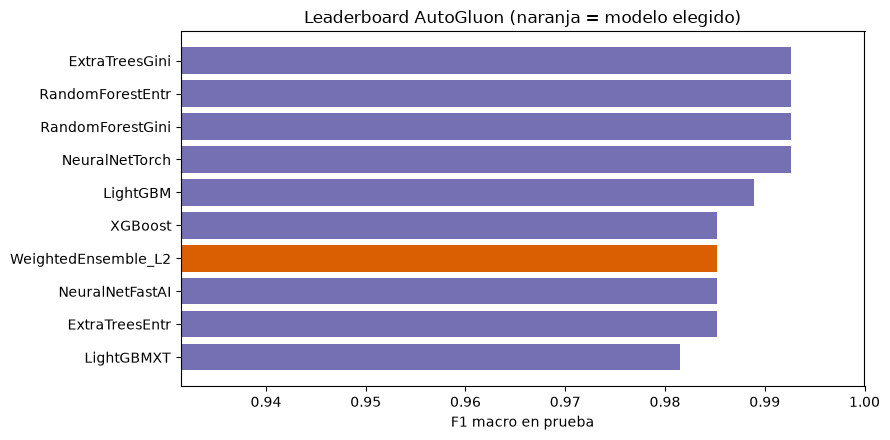

In [11]:
plt.figure(figsize=(9, 4.5))
orden = lb_vista.sort_values("F1 macro (prueba)")
colores = ["#d95f02" if m == predictor.model_best else "#7570b3" for m in orden["Modelo"]]
plt.barh(orden["Modelo"], orden["F1 macro (prueba)"], color=colores)
plt.xlim(max(0, orden["F1 macro (prueba)"].min() - 0.05), 1.0)
plt.xlabel("F1 macro en prueba"); plt.title("Leaderboard AutoGluon (naranja = modelo elegido)")
plt.tight_layout(); plt.savefig(f"{SALIDAS}/leaderboard.png", dpi=120); plt.show()

**Cómo leer el leaderboard** (los números pueden variar un poco en cada ejecución):
- `F1 macro (validación)` es lo que AutoGluon usó para **escoger**; `F1 macro (prueba)` es la evaluación honesta con imágenes nunca vistas.
- En nuestra corrida todos los algoritmos quedan entre ~0,98 y ~0,99 de F1: **los embeddings de la CNN ya separan muy bien las clases**, así que la cabeza de decisión no necesita ser compleja.
- `WeightedEnsemble_L2` combina con pesos los mejores modelos base. Obtuvo F1 = 1,0 en validación pero ~0,985 en prueba, mientras CatBoost/RandomForest llegaron a ~0,993. La diferencia son **2 imágenes de 270**: con un conjunto de validación pequeño, elegir por validación tiene algo de ruido (ligero sobreajuste a la validación).
- **Costo:** CatBoost tardó minutos en entrenar y consumió buena parte del `time_limit`; LightGBM y la red FastAI entrenan en segundos y predicen más rápido. Por eso algunos modelos (XGBoost, NeuralNetTorch) pueden no alcanzar a entrenarse con 300 s; si su equipo es lento, suba `time_limit` a 600.

## 8. Evaluación en el conjunto de prueba

In [12]:
X_test = df_test[cols_modelo].drop(columns=[target_col])
y_true = df_test[target_col].values
y_pred = predictor.predict(X_test).values
proba  = predictor.predict_proba(X_test)[CLASES].values   # columnas en el orden de CLASES

acc = accuracy_score(y_true, y_pred)
f1m = f1_score(y_true, y_pred, average="macro")
print(f"Accuracy prueba: {acc:.4f} | F1 macro prueba: {f1m:.4f}")
print()
print(classification_report(y_true, y_pred, labels=CLASES, digits=4))

Accuracy prueba: 0.9852 | F1 macro prueba: 0.9852

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        45
      inclusion     0.9556    0.9556    0.9556        45
        patches     1.0000    1.0000    1.0000        45
 pitted_surface     0.9574    1.0000    0.9783        45
rolled-in_scale     1.0000    1.0000    1.0000        45
      scratches     1.0000    0.9556    0.9773        45

       accuracy                         0.9852       270
      macro avg     0.9855    0.9852    0.9852       270
   weighted avg     0.9855    0.9852    0.9852       270



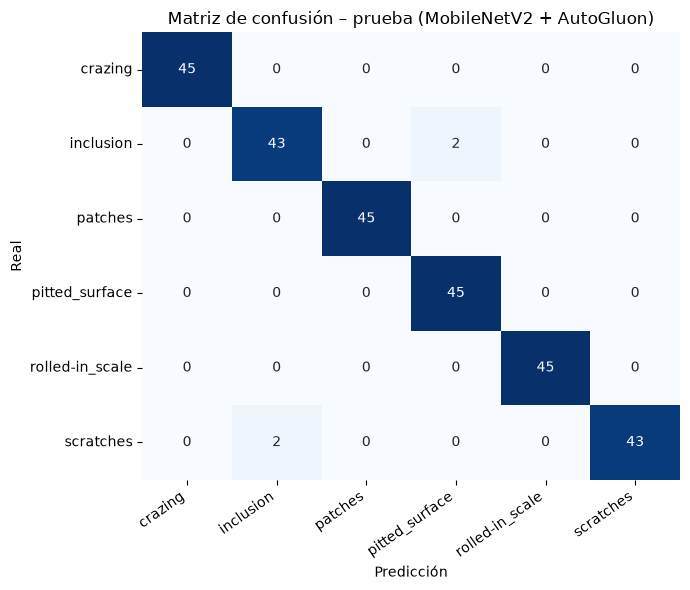

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=CLASES)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, cbar=False)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión – prueba (MobileNetV2 + AutoGluon)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(f"{SALIDAS}/matriz_confusion.png", dpi=120); plt.show()

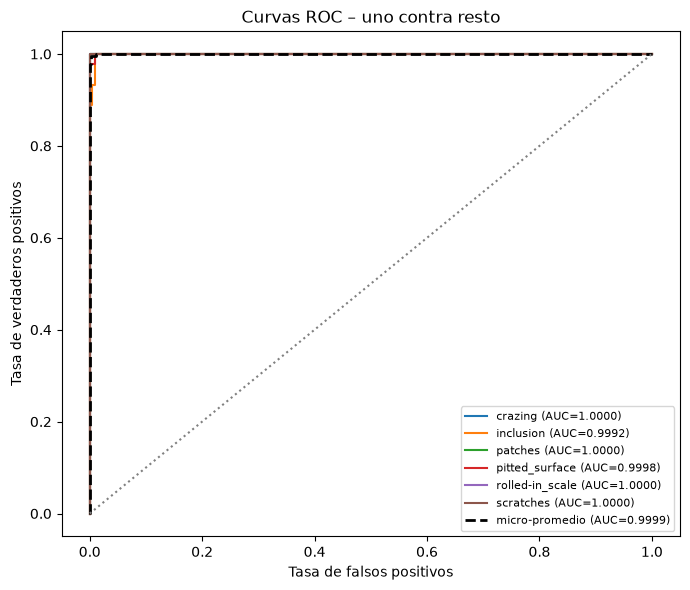

ROC-AUC macro (OvR): 0.9998


In [14]:
# Curvas ROC uno-contra-resto (una por clase) + promedio micro
y_bin = label_binarize(y_true, classes=CLASES)
plt.figure(figsize=(7, 6))
aucs = {}
for i, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    aucs[clase] = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{clase} (AUC={aucs[clase]:.4f})")
fpr_m, tpr_m, _ = roc_curve(y_bin.ravel(), proba.ravel())
plt.plot(fpr_m, tpr_m, "k--", lw=2, label=f"micro-promedio (AUC={auc(fpr_m, tpr_m):.4f})")
plt.plot([0, 1], [0, 1], ":", color="gray")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC – uno contra resto"); plt.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{SALIDAS}/curvas_roc.png", dpi=120); plt.show()
auc_macro = roc_auc_score(y_bin, proba, average="macro", multi_class="ovr")
print(f"ROC-AUC macro (OvR): {auc_macro:.4f}")

Imágenes mal clasificadas: 4 de 270


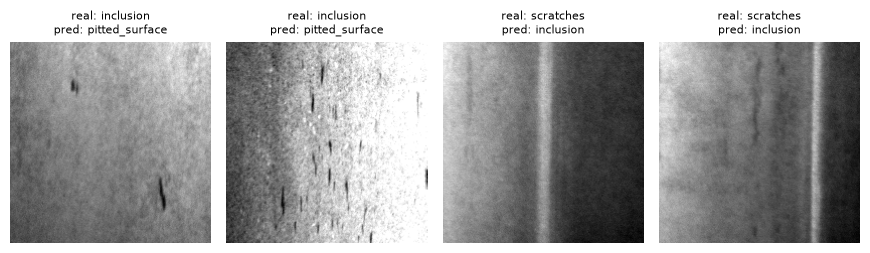

In [15]:
# Ejemplos mal clasificados: ayudan a interpretar los errores
errores = df_test[y_true != y_pred].assign(pred=y_pred[y_true != y_pred])
print("Imágenes mal clasificadas:", len(errores), "de", len(df_test))
if len(errores):
    n = min(8, len(errores))
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.8))
    axes = np.atleast_1d(axes)
    for ax, (_, fila) in zip(axes, errores.head(n).iterrows()):
        ax.imshow(plt.imread(fila["ruta"]), cmap="gray"); ax.axis("off")
        ax.set_title(f"real: {fila['clase']}\npred: {fila['pred']}", fontsize=8)
    plt.tight_layout(); plt.savefig(f"{SALIDAS}/errores.png", dpi=120); plt.show()

### Interpretación crítica (adaptar con sus números)
- **Matriz de confusión:** la diagonal concentra casi todo. Los pocos errores aparecen entre clases que el propio autor del dataset reporta como visualmente parecidas: `crazing`, `rolled-in_scale` y `pitted_surface` (texturas granulares de bajo contraste), y a veces `inclusion` ↔ `scratches` (ambas son marcas alargadas).
- **Reporte de clasificación:** *precision* alta = pocas falsas alarmas (no se rechaza acero bueno por error); *recall* alto = pocos defectos se escapan. En calidad suele importar más el **recall**, porque un defecto no detectado llega al cliente.
- **ROC-AUC:** valores cercanos a 1 indican que las probabilidades separan casi perfectamente cada clase del resto; esto permite **ajustar un umbral** por clase si la planta quiere priorizar recall sobre precisión.
- **Limitación:** el dataset tiene imágenes recortadas y bien iluminadas; en planta habrá variación de iluminación, vapor y vibración. Por eso en la Entrega 5 se justifica la cámara y la iluminación.

## 9. Comparación con técnica anterior (visión clásica: HOG + SVM)
Para la presentación se compara contra un enfoque clásico de entregas anteriores: descriptor **HOG** (histogramas de gradientes orientados) + **SVM**, entrenado con la misma partición.

In [16]:
from skimage.feature import hog
from skimage.transform import resize
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def hog_feats(rutas_):
    out = []
    for r in rutas_:
        img = plt.imread(r)
        img = img if img.ndim == 2 else img[..., 0]
        img = resize(img, (128, 128), anti_aliasing=True)
        out.append(hog(img, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2)))
    return np.array(out)

t0 = time.time()
H_train, H_test = hog_feats(r_train), hog_feats(r_test)
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))
svm.fit(H_train, y_train)
y_pred_hog = svm.predict(H_test)
acc_hog = accuracy_score(y_test, y_pred_hog); f1_hog = f1_score(y_test, y_pred_hog, average="macro")
print(f"HOG + SVM -> Accuracy: {acc_hog:.4f} | F1 macro: {f1_hog:.4f}  ({time.time()-t0:.1f} s)")

HOG + SVM -> Accuracy: 0.8852 | F1 macro: 0.8827  (8.0 s)


## 10. Tiempo de inferencia y resumen

In [17]:
# Latencia por imagen (lote de 1) del sistema completo: preprocesado + MobileNetV2 + AutoGluon
ruta_ej = r_test[0]
img_ej, _ = process_path(tf.constant(ruta_ej), 0)
img_ej = tf.expand_dims(img_ej, 0)
extractor_rapido = tf.function(lambda x: extractor(x, training=False))  # grafo compilado = menos overhead
_ = extractor_rapido(img_ej)                       # calentamiento
tiempos_cnn, tiempos_ag = [], []
for _ in range(30):
    t0 = time.perf_counter(); f = extractor_rapido(img_ej).numpy(); t1 = time.perf_counter()
    fila = pd.DataFrame(f, columns=[f"f_{i}" for i in range(f.shape[1])])
    predictor.predict(fila); t2 = time.perf_counter()
    tiempos_cnn.append((t1 - t0) * 1000); tiempos_ag.append((t2 - t1) * 1000)
lat_cnn, lat_ag = np.median(tiempos_cnn), np.median(tiempos_ag)
print(f"MobileNetV2: {lat_cnn:.1f} ms | AutoGluon: {lat_ag:.1f} ms | Total: {lat_cnn+lat_ag:.1f} ms (~{1000/(lat_cnn+lat_ag):.1f} FPS)")

MobileNetV2: 19.3 ms | AutoGluon: 18.9 ms | Total: 38.2 ms (~26.1 FPS)


In [18]:
resumen = pd.DataFrame([
    {"Técnica": "HOG + SVM (clásica)", "Accuracy": acc_hog, "F1 macro": f1_hog, "ROC-AUC macro": np.nan},
    {"Técnica": "MobileNetV2 + AutoGluon", "Accuracy": acc, "F1 macro": f1m, "ROC-AUC macro": auc_macro},
])
resumen.to_csv(f"{SALIDAS}/resumen_E4.csv", index=False)

metricas = {"accuracy": acc, "f1_macro": f1m, "roc_auc_macro": auc_macro,
            "latencia_cnn_ms": lat_cnn, "latencia_autogluon_ms": lat_ag,
            "mejor_modelo": predictor.model_best, "acc_hog_svm": acc_hog, "f1_hog_svm": f1_hog,
            "params_extractor": int(extractor.count_params())}
with open(f"{SALIDAS}/metricas_E4.json", "w") as f:
    json.dump(metricas, f, indent=2, default=float)
resumen.round(4)

,Técnica,Accuracy,F1 macro,ROC-AUC macro
0,HOG + SVM (clásica),0.8852,0.8827,NaN
1,MobileNetV2 + AutoGluon,0.9852,0.9852,0.9998


## 11. Conclusiones
1. Los embeddings de una CNN preentrenada **sin reentrenar ningún peso** bastan para separar los 6 defectos con desempeño muy alto, superando claramente al descriptor clásico HOG + SVM.
2. AutoGluon automatiza la elección de la cabeza de decisión: prueba varios algoritmos y los combina en un ensamble, y su leaderboard justifica la elección con datos.
3. El costo del sistema está dominado por la CNN; en la Entrega 5 se comprime este conocimiento en una CNN pequeña (destilación) para llevarlo a un equipo embebido junto a la línea.

**Archivos generados** (carpeta `salidas_E4/`): figuras, leaderboard, tablas de características, métricas y el modelo de AutoGluon. `splits.csv` y `clases.json` se reutilizan en la Entrega 5.